In [1]:
import tensorflow as tf
import tensorflow_hub as hub
import matplotlib.pyplot as plt
import numpy as np

print("TensorFlow Version:", tf.__version__)
print("Neural Style Transfer Setup Completed!")

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


TensorFlow Version: 2.21.0
Neural Style Transfer Setup Completed!


In [2]:
import tensorflow_hub as hub

hub_model = hub.load(
    "https://tfhub.dev/google/magenta/arbitrary-image-stylization-v1-256/2"
)

print("Neural Style Transfer Model Loaded Successfully!")

Neural Style Transfer Model Loaded Successfully!


In [6]:
from google.colab import files

uploaded = files.upload()

Saving Screenshot 2026-11-02 at 9.55.01 PM.png to Screenshot 2026-11-02 at 9.55.01 PM (2).png
Saving Screenshot 2026-11-02 at 9.56.16 PM.png to Screenshot 2026-11-02 at 9.56.16 PM.png


In [8]:
print(uploaded.keys())

dict_keys(['Screenshot 2026-11-02 at 9.55.01\u202fPM (2).png', 'Screenshot 2026-11-02 at 9.56.16\u202fPM.png'])


In [9]:
import tensorflow as tf
import matplotlib.pyplot as plt

content_image = tf.keras.utils.load_img(
    "Screenshot 2026-11-02 at 9.55.01 PM (2).png",
    target_size=(256, 256)
)

style_image = tf.keras.utils.load_img(
    "Screenshot 2026-11-02 at 9.56.16 PM.png",
    target_size=(256, 256)
)

content_image = tf.keras.utils.img_to_array(content_image) / 255.0
style_image = tf.keras.utils.img_to_array(style_image) / 255.0

content_image = tf.expand_dims(content_image, 0)
style_image = tf.expand_dims(style_image, 0)

print("Both images loaded successfully!")

Both images loaded successfully!


Neural Style Transfer Completed Successfully!


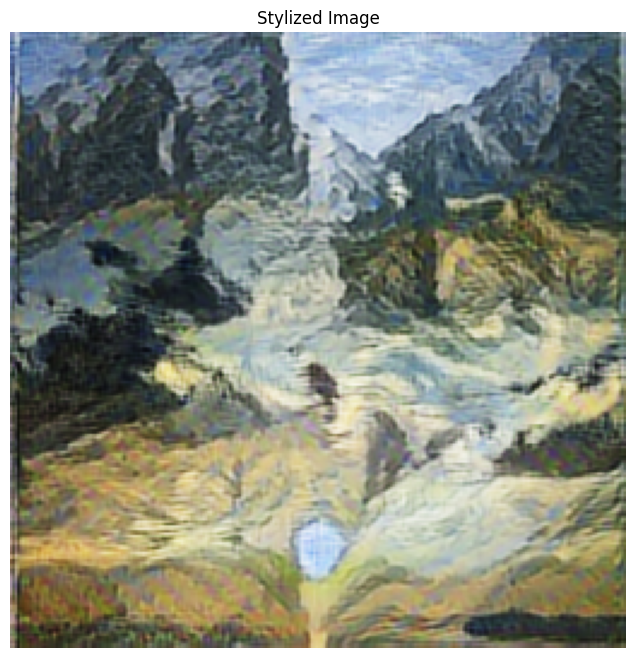

In [10]:
outputs = hub_model(
    tf.constant(content_image),
    tf.constant(style_image)
)

stylized_image = outputs[0]

print("Neural Style Transfer Completed Successfully!")

plt.figure(figsize=(8, 8))
plt.imshow(stylized_image[0])
plt.axis("off")
plt.title("Stylized Image")
plt.show()

In [11]:
output_image = (stylized_image[0].numpy() * 255).clip(0, 255).astype("uint8")

plt.imsave("neural_style_transfer_output.png", output_image)

from google.colab import files
files.download("neural_style_transfer_output.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>